<img src="https://uwe-cyber.github.io/images/uwe_banner.png">

# UFCFEL Security Data Analytics and Visualisation
## Portfolio Assignment: Part 2
### Academic year: 2025-26
## Conduct a security investigation to examine and classify different malware characteristics
---

For this task, the company **UWEtech** have enlisted your support as a security data analyst once again. They believe they have found malware on some of their workstations; however they do not know what malware it is. They also believe that some machines may be infected with different kinds of malware. They have asked you to identify what malware is running on each of the contaminated machines, so that they may understand more about how this incident has occurred on their corporate network.

**Dataset:** You will be issued a dataset for this task via GitLab: https://gitlab.uwe.ac.uk/a23-mccarthy/sdav-2025

**This exercise carries a weight of 30% towards your overall portfolio submission**

### Submission Documents
---

For Part 2 of your portfolio, your complete output file should be saved as:

- **STUDENT_ID-PART2.ipynb**

This should then be included in a ZIP file along with your other two portfolio documents.

The deadline for your portfolio submission is **THURSDAY 11th DECEMBER @ 14:00**. 


In [2]:
# numpy = maths on arrays, pandas = tables (DataFrames), matplotlib = charts.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# One consistent chart style for the whole notebook.
INK, MUTED, GRID = '#191919', '#5f6368', '#e3e6ea'
# rcParams are matplotlib's default settings, so setting them once here styles every later chart.
plt.rcParams.update({
    'figure.dpi': 120, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.family': 'DejaVu Sans', 'font.size': 11, 'text.color': INK,
    'axes.titlesize': 17, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 12, 'axes.labelweight': 'bold', 'axes.labelcolor': INK,
    'axes.edgecolor': '#b8bdc4', 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'legend.frameon': False
})

def add_titles(ax, title, subtitle):
    """Add a bold title with a lighter explanatory line beneath it."""
    # pad leaves a gap (in points) above the plot for the subtitle.
    ax.set_title(title, pad=34)
    # xycoords='axes fraction' makes (0, 1) the top-left corner of the plot, whatever the data range.
    ax.annotate(subtitle, xy=(0, 1), xycoords='axes fraction', xytext=(0, 12),
                textcoords='offset points', color=MUTED, fontsize=11)

# header=None because the file has no column names, so pandas numbers them 0 to 255.
# Each row is one system and each column is one feature.
features = pd.read_csv('./part2/malware_data.csv', header=None)
features

,0,1,2,3,4,5,6,7,8,9,...,246,247,248,249,250,251,252,253,254,255
0,224862.0,15842.0,12985.0,7387.0,13132.0,5112.0,8661.0,7990.0,14978.0,5656.0,...,3714.0,2892.0,9344.0,2415.0,2742.0,3023.0,11949.0,3662.0,5552.0,77433.0
1,21802.0,2127.0,2076.0,2028.0,1871.0,1622.0,1939.0,1502.0,2133.0,1689.0,...,1664.0,1607.0,1788.0,1394.0,1327.0,1453.0,1785.0,1559.0,1755.0,4882.0
2,24407.0,11682.0,7189.0,6538.0,7687.0,6848.0,4974.0,5377.0,7049.0,11642.0,...,5795.0,6053.0,6426.0,5435.0,4961.0,5026.0,5376.0,4180.0,5685.0,5775.0
3,7132.0,461.0,647.0,371.0,581.0,269.0,646.0,262.0,243.0,165.0,...,151.0,276.0,299.0,294.0,294.0,354.0,506.0,569.0,940.0,1516.0
4,5321.0,1108.0,985.0,955.0,958.0,890.0,971.0,919.0,945.0,963.0,...,933.0,975.0,945.0,924.0,879.0,952.0,956.0,900.0,942.0,1559.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
27995,23849.0,1489.0,1573.0,2649.0,1560.0,1025.0,922.0,1020.0,1042.0,938.0,...,993.0,968.0,1165.0,1041.0,1258.0,1753.0,1203.0,958.0,1315.0,4342.0
27996,9267.0,1056.0,981.0,930.0,1573.0,819.0,879.0,1064.0,1029.0,893.0,...,998.0,911.0,990.0,1039.0,930.0,833.0,904.0,891.0,976.0,2683.0
27997,25357.0,874.0,1008.0,2781.0,1518.0,939.0,4267.0,968.0,1103.0,1032.0,...,563.0,557.0,974.0,706.0,514.0,632.0,657.0,584.0,535.0,2431.0
27998,29010.0,6476.0,2969.0,5358.0,2827.0,4598.0,2172.0,4045.0,2496.0,3718.0,...,217.0,146.0,544.0,232.0,95.0,140.0,294.0,163.0,182.0,4005.0


In [3]:
# The label file says which malware family each row of features belongs to.
labels = pd.read_csv('./part2/malware_label.csv', header=None)
# axis=1 drops column 0, which is not needed because the rows are in the same order as features.
labels = labels.drop(0, axis=1)
# Give the remaining column a meaningful name.
labels = labels.rename(columns = {1:'label'})
# Count the rows per family: 2,000 each, so the classes are balanced and accuracy is a fair measure.
labels.value_counts()

label     
high          2000
emotet        2000
dealply       2000
filetour      2000
flystudio     2000
upatre        2000
razy          2000
gandcrab      2000
wannacry      2000
bladabindi    2000
startsurf     2000
gamarue       2000
vittalia      2000
zbot          2000
Name: count, dtype: int64

In this dataset, we have collected data from 28000 systems (rows), where each system reports 256 parameters (columns).

We will first look at developing a small classifier "by hand", to help you understand how the classifier works, and then we will look at using the full dataset on more powerful classifiers to see whether we can classify the different malware varients on the set of workstations.

## Part 1: Developing a small classifier "by hand"

### Do not modify this cell

In [4]:
# DO NOT MODIFY THIS CELL
mal1_index = 17000
mal2_index = 21000
mal3_index = 12000
mal_range = 50
mal_test_range = 30

train_data = np.vstack([ features[mal1_index:mal1_index+mal_range][[0,1]].values, features[mal2_index:mal2_index+mal_range][[0,1]].values, features[mal3_index:mal3_index+mal_range][[0,1]].values ])
train_data = pd.DataFrame(train_data)
train_labels = np.vstack([ labels[mal1_index:mal1_index+mal_range].values, labels[mal2_index:mal2_index+mal_range].values, labels[mal3_index:mal3_index+mal_range].values ])
train_labels = pd.DataFrame(train_labels)
train_data['labels'] = train_labels
train_data = train_data.rename(columns={0:'x', 1:'y'})

test_data = np.vstack([ features[mal1_index+mal_range:mal1_index+mal_range+mal_test_range][[0,1]].values, features[mal2_index+mal_range:mal2_index+mal_range+mal_test_range][[0,1]].values, features[mal3_index+mal_range:mal3_index+mal_range+mal_test_range][[0,1]].values ])
test_data = pd.DataFrame(test_data)
test_labels = np.vstack([ labels[mal1_index+mal_range:mal1_index+mal_range+mal_test_range].values, labels[mal2_index+mal_range:mal2_index+mal_range+mal_test_range].values, labels[mal3_index+mal_range:mal3_index+mal_range+mal_test_range].values ])
test_labels = pd.DataFrame(test_labels)
test_data['labels'] = test_labels
test_data = test_data.rename(columns={0:'x', 1:'y'})

train_data

,x,y,labels
0,3114896.0,10815.0,wannacry
1,3436940.0,9551.0,wannacry
2,1812649.0,15343.0,wannacry
3,3067845.0,10541.0,wannacry
4,51591.0,21367.0,wannacry
...,...,...,...
145,78591.0,7734.0,razy
146,80429.0,5114.0,razy
147,2898.0,98.0,razy
148,183376.0,8477.0,razy


We now have a smaller sample of data to work with called train_data, that has three malware families included, and we have reduced the number of features to make it easier to understand the process of how the classifier operates.

### Question 1: Find the Centroid point of each of the three groups
#### (2 marks)

*Hint: We have filtered the sample to a new variable called **train_data**. Also, think about how to find the mid-point of a set of co-ordinate points **x** and **y**.*

In [5]:
# Select each family's training rows and the two plotted features. Their means
# give the family's centre as a [x, y] NumPy array (its centroid).
# The provided cell above builds train_data (50 rows per family) and test_data (the NEXT 30 rows per family),
# so no test row is used for training. np.vstack stacks the three families on top of each other.
#
# .loc[rows, columns]: the test picks one family's rows, and ['x', 'y'] picks the two features.
# mean() averages each column; to_numpy() gives a plain array such as [mean_x, mean_y].
wannacry_centroid = train_data.loc[train_data['labels'] == 'wannacry', ['x', 'y']].mean().to_numpy()
razy_centroid = train_data.loc[train_data['labels'] == 'razy', ['x', 'y']].mean().to_numpy()
startsurf_centroid = train_data.loc[train_data['labels'] == 'startsurf', ['x', 'y']].mean().to_numpy()

print ("Wannacry: ", wannacry_centroid)
print ("Razy: ", razy_centroid)
print ("Startsurf: ", startsurf_centroid)

Wannacry:  [2181660.66   11087.1 ]
Razy:  [100505.22   6158.28]
Startsurf:  [478778.12   3754.04]


### Question 2: Create a Scatter Plot that shows both the train data and the corresponding centroids. Colour-code your data by group, and use a different visual marker for the centroid.

#### (2 marks)

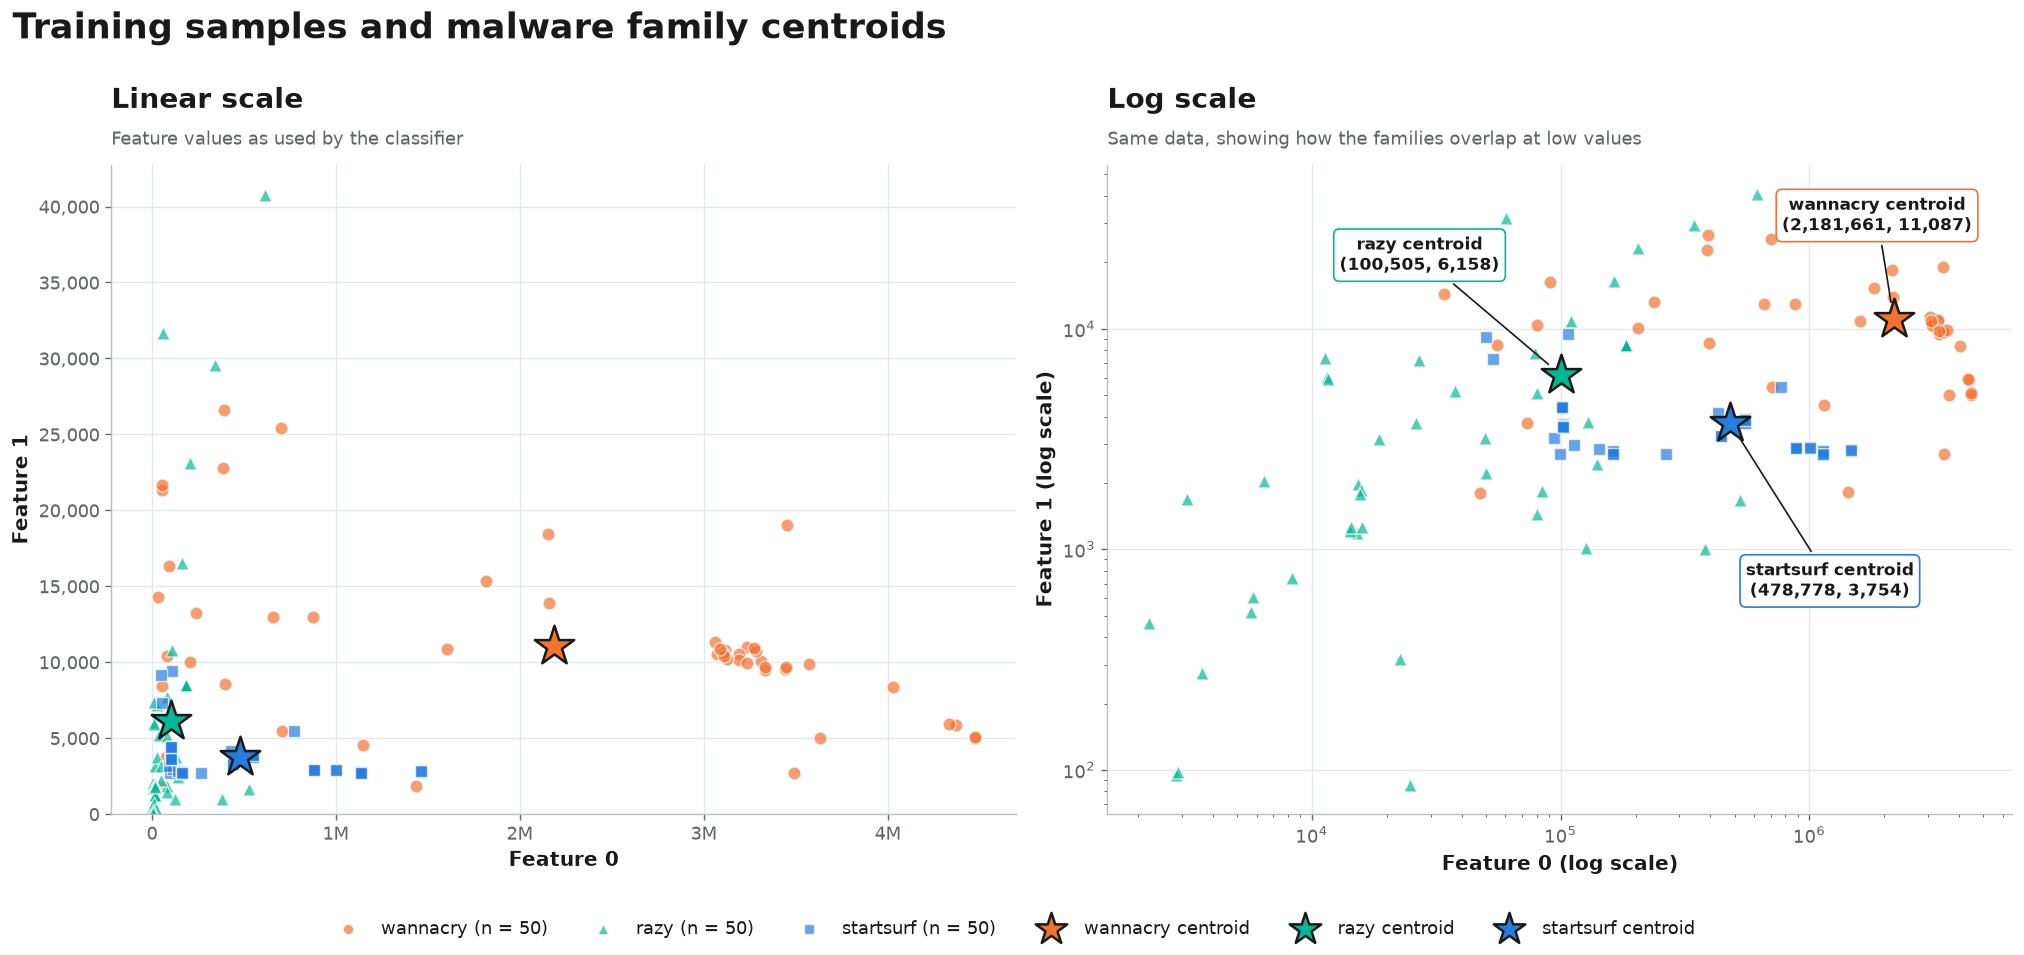

In [ ]:
# Use the same colour and marker for each family in both panels (a colour-blind safe palette).
# Each family maps to a pair: (colour, marker shape).
class_styles = {'wannacry': ('#f47230', 'o'), 'razy': ('#00b894', '^'), 'startsurf': ('#257de0', 's')}
centroids = {'wannacry': wannacry_centroid, 'razy': razy_centroid, 'startsurf': startsurf_centroid}

# The linear panel shows true distances, as used by the classifier. The log panel spreads out
# the tightly packed low values.
# subplots(1, 2) = one row and two columns of plots. Looping over axes draws the same data on both.
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for ax in axes:
    # Plot each family's training samples.
    # .items() gives each key and value; (color, marker) unpacks the pair.
    for malware, (color, marker) in class_styles.items():
        group = train_data[train_data['labels'] == malware]
        ax.scatter(group['x'], group['y'], color=color, marker=marker, s=60, alpha=0.7,
                   edgecolor='white', linewidth=0.8, label=f'{malware} (n = {len(group)})')
    # Overlay each family's centroid as a large star in the same colour.
    for malware, (cx, cy) in centroids.items():
        ax.scatter(cx, cy, color=class_styles[malware][0], marker='*', s=620, edgecolor=INK,
                   linewidth=1.5, zorder=5, label=f'{malware} centroid')

# Label each centroid on the log panel, where there is enough space around them.
# Hand-set label positions (in points) that avoid covering the data.
label_offsets = {'wannacry': (-10, 62), 'razy': (-85, 72), 'startsurf': (60, -95)}
for malware, (cx, cy) in centroids.items():
    axes[1].annotate(f'{malware} centroid\n({cx:,.0f}, {cy:,.0f})', (cx, cy), xytext=label_offsets[malware],
                     textcoords='offset points', ha='center', va='center', fontsize=10, fontweight='bold', zorder=6,
                     bbox=dict(boxstyle='round,pad=0.35', fc='white', ec=class_styles[malware][0]),
                     arrowprops=dict(arrowstyle='-', color=INK, linewidth=1, shrinkB=10))

# A lambda is a small unnamed function; this one writes 2000000 as 2M.
axes[0].xaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v / 1e6:g}M' if v else '0'))
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
axes[0].set_ylim(bottom=0)
add_titles(axes[0], 'Linear scale', 'Feature values as used by the classifier')
axes[0].set(xlabel='Feature 0', ylabel='Feature 1')

# On a log scale each step multiplies by 10, so small values get more space.
axes[1].set(xscale='log', yscale='log')
add_titles(axes[1], 'Log scale', 'Same data, showing how the families overlap at low values')
axes[1].set(xlabel='Feature 0 (log scale)', ylabel='Feature 1 (log scale)')

fig.suptitle('Training samples and malware family centroids', x=0.01, ha='left', fontsize=21, fontweight='bold')
# Both panels have the same legend, so collect it once and put it under the whole figure.
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc='lower center', ncol=6, fontsize=11, markerscale=0.8)
# rect keeps space free at the bottom for the legend and at the top for the title.
plt.tight_layout(rect=(0, 0.06, 1, 0.98))
plt.show()

### Question 3a: For each point in test_data, calculate the Euclidean distance between the point and each of the three centroid points 

#### (3 marks)

### Question 3b: Use the closest centroid to assign membership and compare against the test data label to obtain a score of successful classifications 

#### (3 marks)

*Hint: You may find the clustering activity worksheet helpful for how to approach this task, and you will likely want to answer both questions within the same for loop below.*

In [7]:
score = 0
predictions = []

# Classify each test sample using its two feature coordinates.
# shape[0] is the number of rows (90), so i runs from 0 to 89.
for i in range(test_data.shape[0]):
    
    # Calculate Euclidean distance from this sample to each centroid:
    # Euclidean distance (Pythagoras): sqrt((x1 - x2)^2 + (y1 - y2)^2). ** 2 means squared.
    # A centroid is [x, y], so [0] is its x value and [1] is its y value.
    # Feature 0 is far larger than feature 1, so it dominates the distance; this is why scaling (Question 5) matters.
    distance1 = np.sqrt((test_data.loc[i, 'x'] - wannacry_centroid[0]) ** 2 +
                        (test_data.loc[i, 'y'] - wannacry_centroid[1]) ** 2)
    distance2 = np.sqrt((test_data.loc[i, 'x'] - razy_centroid[0]) ** 2 +
                        (test_data.loc[i, 'y'] - razy_centroid[1]) ** 2)
    distance3 = np.sqrt((test_data.loc[i, 'x'] - startsurf_centroid[0]) ** 2 +
                        (test_data.loc[i, 'y'] - startsurf_centroid[1]) ** 2)
    
    # Keep labels in the same order as distances, so the smallest distance
    # selects the label of the nearest centroid.
    distances = [distance1, distance2, distance3]
    dist_labels = ['wannacry', 'razy', 'startsurf']
    
    # Compare the nearest-centroid prediction with the known test label;
    # increment the score only when they match.
    # argmin() gives the POSITION of the smallest distance (0, 1 or 2), which picks the matching label.
    predicted_label = dist_labels[np.argmin(distances)]
    # Store the prediction so that the results can also be shown per family below.
    predictions.append(predicted_label)
    if predicted_label == test_data.loc[i, 'labels']:
        score += 1
    
print ("Score:", score)

# crosstab() counts each actual/predicted pair. The diagonal holds the correct predictions,
# so every other number is a mistake, which shows which families overlap.
family_results = pd.crosstab(test_data['labels'], pd.Series(predictions),
                             rownames=['Actual'], colnames=['Predicted'])
print("\nActual family (rows) against predicted family (columns):")
print(family_results)

# Compare the spread of the two features. The larger one dominates the Euclidean distance.
print("\nStandard deviation of each training feature:")
print(train_data[['x', 'y']].std(ddof=0).round(0).to_string())

Score: 63

Actual family (rows) against predicted family (columns):
Predicted  razy  startsurf  wannacry
Actual                              
razy         30          0         0
startsurf    12         15         3
wannacry      8          4        18

Standard deviation of each training feature:
x    1279416.0
y       6628.0


### Task 4: Provide a final accuracy score for the performance of your "by hand" classifier 

#### (1 marks)

In [8]:

# Divide correct predictions by the number of test samples to get accuracy..
# accuracy = correct predictions / all predictions. :.2% shows 0.7 as 70.00%.
accuracy = score / test_data.shape[0]
print(f"Accuracy: {score}/{test_data.shape[0]} = {accuracy:.2%}")

Accuracy: 63/90 = 70.00%


## Part 2: Developing a large-scale ML classifier

We will now extend the earlier principles for the full dataset. Essentially the task is the same, we want to find the parameters that allow us to clearly separate groups for classification. You will want to consult the [scikit-learn documentation](https://scikit-learn.org/stable/index.html) to answer the following questions.

### Question 5: Scale the Features DataFrame using the StandardScaler function 

#### (1 mark)

*Hint: The variable **features** contains all of the numerical parameters that we will use to train our ML model, which we need to normalise using this function.*

In [9]:
# StandardScaler standardizes each feature using its mean and standard deviation,
# so features with different numeric ranges are more comparable to the MLP.
from sklearn.preprocessing import StandardScaler

# Learn the scaling values and apply them to all feature rows.
# For a strictly unbiased test, fit the scaler on X_train only after splitting,
# then use that fitted scaler to transform X_test.
# New value = (value - mean) / standard deviation, so each column ends with mean 0 and std 1.
# fit = learn the mean and std; transform = apply them; fit_transform does both.
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

### Question 6: Use the LabelEncoder function on the Labels variable to obtain numerical label data 

#### (1 mark)

In [10]:
# LabelEncoder converts the family names into integer class IDs for scikit-learn.
from sklearn.preprocessing import LabelEncoder

# Learn one consistent name-to-number mapping and encode every row's target label.
# Families are numbered alphabetically from 0. The numbers are only names: 5 is not 'bigger' than 2.
# label_encoder.inverse_transform() would convert the numbers back into names.
label_encoder = LabelEncoder()
labels_encoded = label_encoder.fit_transform(labels['label'])

### Question 7: Prepare the dataset for ML testing using the Train-Test-Split function
#### (1 mark)

In [11]:
# Separate the data used to train the model from the data used only for evaluation.
from sklearn.model_selection import train_test_split

# X = the features (inputs) and y = the labels (answers). The function returns four pieces in this order.
# Testing on unseen rows shows whether the model generalises or has only memorised the training data.
X_train, X_test, y_train, y_test = train_test_split(
    features_scaled,
    labels_encoded,
    test_size=0.2,  # Hold out 20% of the rows for evaluation.
    random_state=42,  # Use a fixed seed so the split is repeatable.
    stratify=labels_encoded  # Keep each class's proportion similar in both subsets.
)

### Question 8: Use a Multi-Layer Perceptron (MLP) classifier to train a machine learning model, and obtain the accuracy score against your test data. 

#### (3 marks)

In [12]:
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier

# Configure one hidden layer with 100 neurons
# Early_stopping halts if validation performance stops improving.
# The fixed seed makes the model's random choices reproducible.
# An MLP is a neural network: 256 inputs -> 100 hidden neurons -> 14 outputs (one per family).
# max_iter is the largest number of passes (epochs) over the training data.
# early_stopping keeps back 10% of the training data to decide when to stop, which limits overfitting.
mlp_classifier = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=200,
    random_state=42,
    early_stopping=True
)
# Learn the relationship between the training features and their encoded labels.
# fit() is the training step; predict() then uses the trained model.
mlp_classifier.fit(X_train, y_train)
# Predict labels for unseen test rows and calculate the proportion predicted correctly.
mlp_predictions = mlp_classifier.predict(X_test)
mlp_accuracy = accuracy_score(y_test, mlp_predictions)
print(f"MLP accuracy: {mlp_accuracy:.2%}")

MLP accuracy: 78.00%


### Question 9: Use a Random Forest (RF) classifier to train a machine learning model, and obtain the accuracy score against your test data. 

#### (3 marks)

In [13]:
from sklearn.ensemble import RandomForestClassifier

# Build 100 trees, fix the seed for reproducibility, and use available CPU cores
# to fit the independent trees in parallel.
# A random forest trains many decision trees on random samples of the data and combines their predictions.
# Trees split one feature at a time (is feature 3 > 0.5?), so they do not depend on feature scaling.
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
# Train on the same training subset as the MLP for a fair comparison.
rf_classifier.fit(X_train, y_train)
# Predict the held-out labels, then calculate and print the correct-prediction rate.
rf_predictions = rf_classifier.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_predictions)
print(f"Random Forest accuracy: {rf_accuracy:.2%}")

Random Forest accuracy: 87.98%


### Question 10: Describe what you believe are the key findings of this task, comparing the *by-hand* classifier with the MLP classifier. As part of your discussion, consider the volume of data in both approaches and the issues of data separability. Give justifications for your answer. Limit your response to a maximum of 300 words.

#### (10 marks).

The by-hand classifier correctly identified 63 of 90 samples (70.00%), while the MLP achieved 78.00%. These are not directly comparable: random guessing would give 33.3% across three families, but only 7.1% across 14. The MLP therefore performed better on a much harder task.

Data volume: The by-hand model used 150 training samples and two features, whereas the MLP used 22,400 samples and all 256 features. More examples represent each family's variation better, and more features provide more information to distinguish them. Test size also matters: each by-hand prediction changes accuracy by 1.1 percentage points, so the MLP's 5,600-sample estimate is more reliable.

Separability: The scatter plot shows families overlapping at low values. All 30 razy samples were correct, but only 18 wannacry and 15 startsurf, with most errors predicted as razy. Wannacry is widely spread, so its mean is a poor representation of many samples. Nearest-centroid also only creates straight boundaries, while the MLP can learn non-linear ones. Additionally, feature 0's standard deviation is approximately 1.28 million, compared with 6,628 for feature 1. Without scaling, feature 0 dominates the distance calculation. StandardScaler addresses this for the MLP.

Limitations: The MLP still misclassified 22% of samples, so families remain partly inseparable with this configuration. Random Forest reached 87.98% on the same split, showing that model choice matters as well as data volume. The scaler was fitted before splitting, so test information may have slightly inflated the MLP's score. Because the data, features, scaling and algorithm all changed, the improvement cannot be attributed to one factor.

Overall, the by-hand classifier is simple and interpretable, but the MLP scales better to complex, overlapping data. Fitting the scaler on training data only, and examining a confusion matrix, would strengthen the evaluation.